<a href="https://colab.research.google.com/github/pavlek358/DSB-MTN-Git-Starter/blob/main/capstone_clustering_procurement_corrected.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/pavlek358/dsb_capstone/blob/main/capstone_clustering_procurement.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone: clustering public procurement tenders

**Question:** do tenders fall into natural groups, and do some groups look riskier (more delays, more manual reviews)?

**Idea further developed after initial idea of using supervised models:** finding groups without labels (unsupervised), then check the meaning behind the clusters

**Current limitation:** data is synthetic, the features are limited to the dataset I found in one of the previous projects, idea is to test the approach on a real data consequently


## 1. Setup

In [1]:
# Basic tools: numbers, tables and charts
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning tools
from sklearn.preprocessing import StandardScaler                      # puts features on the same scale
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN    # three clustering methods
from sklearn.metrics import silhouette_score                          # how well clusters are separated
from sklearn.neighbors import NearestNeighbors                        # helps pick eps for DBSCAN
from sklearn.decomposition import PCA                                 # squeezes features into 2 for plotting
from scipy.cluster.hierarchy import linkage, dendrogram               # draws the hierarchical tree

## 2. Load the data

In [2]:
# Load the data from the repo's data/ folder (works locally and in Colab); one row = one tender
url = 'https://raw.githubusercontent.com/pavlek358/dsb_capstone/main/data/synthetic_procurement_data.csv'
df = pd.read_csv(url)
print(df.shape)   # (rows, columns)
df.head()         # first 5 rows

(2500, 13)


,procurement_method,category,agency_type,supplier_region,estimated_value,num_bids,supplier_past_contracts,supplier_late_delivery_rate,category_complexity_score,days_to_deadline,has_manual_review_flag,budget_change_count,award_delayed
0,direct_award,it_services,municipal,national,79996.15,4,7,0.289,5,21,0,0,1
1,open_tender,office_supplies,municipal,local,13138.56,5,6,0.120,1,29,0,0,1
2,framework_calloff,logistics,education,regional,16533.26,3,5,0.206,5,91,1,0,0
3,selective_tender,logistics,health,local,139399.70,1,2,0.454,2,66,0,1,1
4,open_tender,medical_supplies,municipal,national,26291.71,5,7,0.170,3,94,0,2,0


## 3. EDA

In [31]:
#columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   procurement_method           2500 non-null   object 
 1   category                     2500 non-null   object 
 2   agency_type                  2500 non-null   object 
 3   supplier_region              2500 non-null   object 
 4   estimated_value              2500 non-null   float64
 5   num_bids                     2500 non-null   int64  
 6   supplier_past_contracts      2500 non-null   int64  
 7   supplier_late_delivery_rate  2500 non-null   float64
 8   category_complexity_score    2500 non-null   int64  
 9   days_to_deadline             2500 non-null   int64  
 10  has_manual_review_flag       2500 non-null   int64  
 11  budget_change_count          2500 non-null   int64  
 12  award_delayed                2500 non-null   int64  
 13  log_value         

### Missing values

In [3]:
# Missing values per column: count and percentage
missing = pd.DataFrame({'missing': df.isna().sum(),
                        'missing_%': (df.isna().mean() * 100).round(2)})
missing.sort_values('missing_%', ascending=False)

,missing,missing_%
procurement_method,0,0.0
category,0,0.0
agency_type,0,0.0
supplier_region,0,0.0
estimated_value,0,0.0
num_bids,0,0.0
supplier_past_contracts,0,0.0
supplier_late_delivery_rate,0,0.0
category_complexity_score,0,0.0
days_to_deadline,0,0.0


In [4]:
# Missing values by category: % of rows with any missing value, for each value of each text column
cat_cols = df.select_dtypes(exclude='number').columns
row_has_missing = df.isna().any(axis=1)
pd.concat({col: (row_has_missing.groupby(df[col]).mean() * 100).round(2) for col in cat_cols}).rename('missing_%').to_frame()

missing_%
procurement_method direct_award             0.0
                   framework_calloff        0.0
                   open_tender              0.0
                   selective_tender         0.0
category           construction             0.0
                   it_services              0.0
                   logistics                0.0
                   medical_supplies         0.0
                   office_supplies          0.0
agency_type        central                  0.0
                   education                0.0
                   health                   0.0
                   municipal                0.0
                   transport                0.0
supplier_region    local                    0.0
                   national                 0.0
                   regional                 0.0

**A:** No missing values in any column or category, so nothing to fill.

### Summary of all columns

In [5]:
# Numeric columns: mean, std, min, max... | text columns: count, unique, top, freq
df.describe(include='all').round(2)

,procurement_method,category,agency_type,supplier_region,estimated_value,num_bids,supplier_past_contracts,supplier_late_delivery_rate,category_complexity_score,days_to_deadline,has_manual_review_flag,budget_change_count,award_delayed
count,2500,2500,2500,2500,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00
unique,4,5,5,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,open_tender,it_services,health,local,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1218,612,518,988,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,33468.79,5.00,7.01,0.20,2.97,63.54,0.19,0.79,0.40
std,NaN,NaN,NaN,NaN,32207.00,2.02,2.68,0.12,1.43,32.94,0.39,0.88,0.49
min,NaN,NaN,NaN,NaN,5000.00,1.00,0.00,0.00,1.00,7.00,0.00,0.00,0.00
25%,NaN,NaN,NaN,NaN,13916.33,4.00,5.00,0.11,2.00,35.00,0.00,0.00,0.00
50%,NaN,NaN,NaN,NaN,23541.97,5.00,7.00,0.18,3.00,64.00,0.00,1.00,0.00
75%,NaN,NaN,NaN,NaN,41652.40,6.00,9.00,0.27,4.00,92.00,0.00,1.00,1.00


**A:** Numeric features are on very different scales, so we scale them later. Text columns: `procurement_method` has 4 values (about half are `open_tender`), `category` 5, `agency_type` 5, `supplier_region` 3.

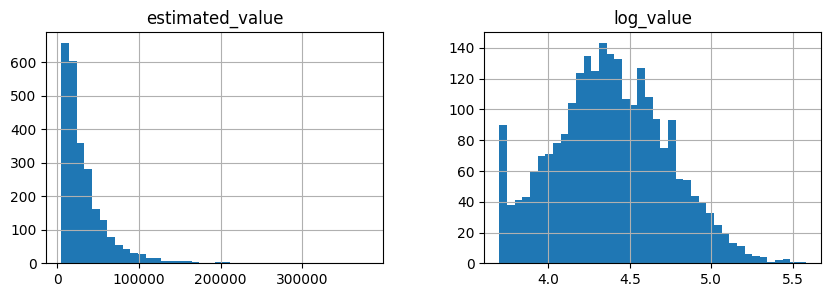

In [6]:
# Contract value is very skewed, so we use log10 of it
df['log_value'] = np.log10(df['estimated_value'])

# Compare the two distributions: raw value vs log value
df[['estimated_value', 'log_value']].hist(bins=40, figsize=(10, 3));

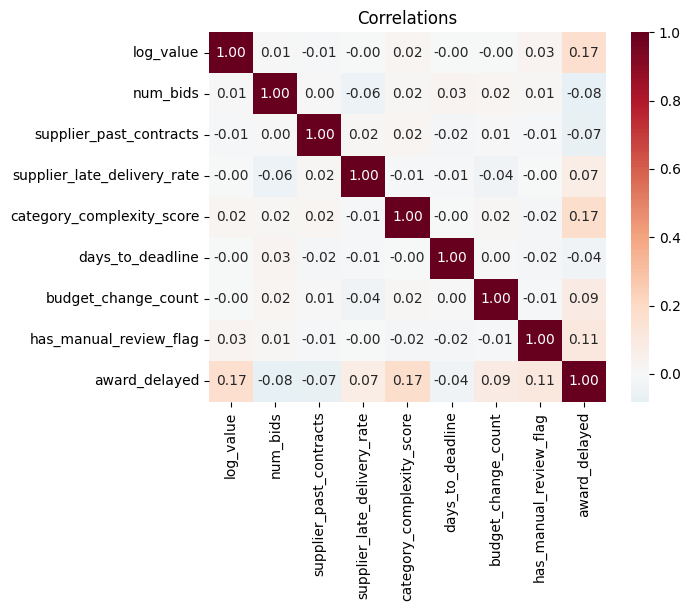

In [7]:
# The 7 numeric features we will cluster on
features = ['log_value', 'num_bids', 'supplier_past_contracts', 'supplier_late_delivery_rate',
            'category_complexity_score', 'days_to_deadline', 'budget_change_count']

# Correlation heatmap: do the features move together? (red = positive, blue = negative)
sns.heatmap(df[features + ['has_manual_review_flag', 'award_delayed']].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Correlations');

**A:** The features are almost uncorrelated with each other. That is a first hint that strong groups may not exist.

### Outliers

log_value                        9
num_bids                        59
supplier_past_contracts          7
supplier_late_delivery_rate     33
category_complexity_score        0
days_to_deadline                 0
budget_change_count            105
dtype: int64
Tenders with at least one outlier: 207 (8.3%)


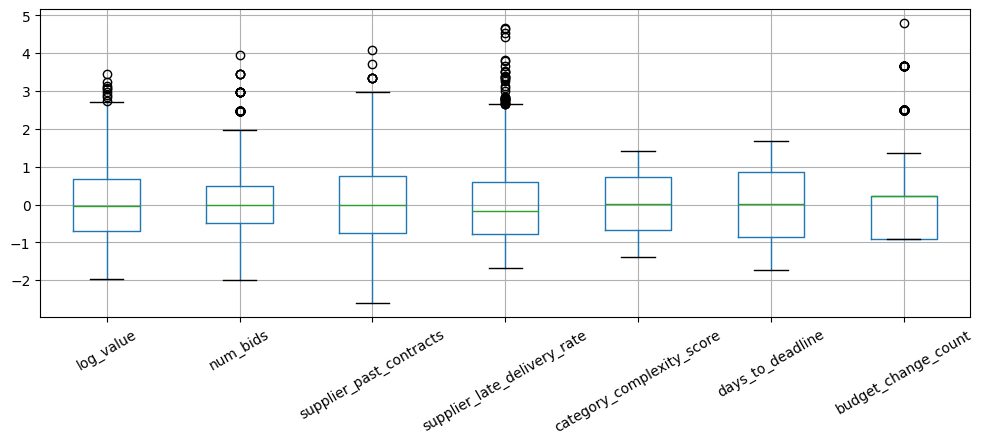

In [8]:
# IQR rule: outlier = below Q1 - 1.5*IQR or above Q3 + 1.5*IQR
q1, q3 = df[features].quantile(0.25), df[features].quantile(0.75)   # 25th and 75th percentile
iqr = q3 - q1                                                        # spread of the middle 50%
outliers = (df[features] < q1 - 1.5 * iqr) | (df[features] > q3 + 1.5 * iqr)   # True = outlier
print(outliers.sum())   # number of outliers per feature
print('Tenders with at least one outlier:', outliers.any(axis=1).sum(), f'({outliers.any(axis=1).mean():.1%})')

# Boxplots on a common scale (z-scores)
z = (df[features] - df[features].mean()) / df[features].std()   # how many std away from average
z.boxplot(figsize=(12, 4), rot=30);

In [9]:
# Look at the 5 most extreme tenders (largest z-score in any feature)
df.loc[z.abs().max(axis=1).sort_values(ascending=False).index[:5]]

,procurement_method,category,agency_type,supplier_region,estimated_value,num_bids,supplier_past_contracts,supplier_late_delivery_rate,category_complexity_score,days_to_deadline,has_manual_review_flag,budget_change_count,award_delayed,log_value
1825,open_tender,construction,education,regional,24032.49,5,10,0.075,2,84,0,5,1,4.380799
913,framework_calloff,it_services,central,national,39270.65,7,2,0.749,4,49,0,0,1,4.594068
243,selective_tender,office_supplies,municipal,local,93823.07,7,10,0.746,3,76,0,1,1,4.972310
2260,selective_tender,construction,central,local,16663.19,4,6,0.732,4,48,0,0,1,4.221758
2192,direct_award,office_supplies,education,local,27444.54,9,8,0.720,1,113,1,1,1,4.438456


In [10]:
# Are tenders with outliers different on the outcomes?
df.groupby(outliers.any(axis=1).rename('has_outlier'))[['award_delayed', 'has_manual_review_flag']].mean().round(2)

,award_delayed,has_manual_review_flag
has_outlier,,
False,0.39,0.19
True,0.47,0.17


**A:** About 8% of tenders have an outlier value. They look like real tenders (many budget changes, many bids, often-late suppliers), not errors, and are delayed more often (47% vs 39%), so we keep them.

## 4. Choose and scale features
We cluster on the 7 numeric tender features. We **keep out** `has_manual_review_flag`, `award_delayed` and the text columns, and use them later to describe the groups (as simple risk checks).

In [11]:
# Clustering uses distances, so every feature must be on the same scale
X = df[features]
scaler = StandardScaler()             # mean 0, standard deviation 1 for each feature
X_scaled = scaler.fit_transform(X)

## 5. K-Means: choose k (elbow + silhouette)

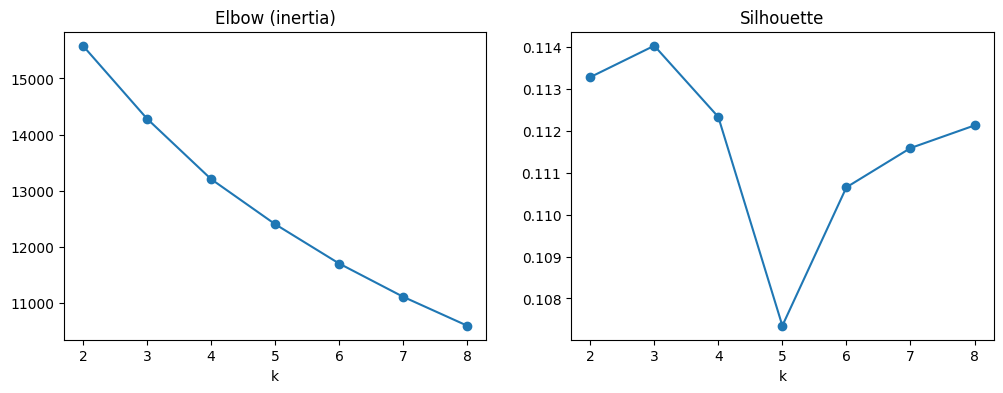

In [12]:
# Try k = 2 to 8 clusters and record two scores for each k
inertia, sil = [], []
k_values = range(2, 9)
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)   # n_init=10: run 10 times, keep the best
    inertia.append(km.inertia_)                                          # inertia: how tight the clusters are (lower = tighter)
    sil.append(silhouette_score(X_scaled, km.labels_))                   # silhouette: how well separated (closer to 1 = better)

# Plot both scores: look for an "elbow" on the left and a peak on the right
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_values, inertia, marker='o'); axes[0].set_title('Elbow (inertia)'); axes[0].set_xlabel('k')
axes[1].plot(k_values, sil, marker='o'); axes[1].set_title('Silhouette'); axes[1].set_xlabel('k');

**A:** No clear elbow, and silhouette is about 0.11 for every k (1 = great, 0 = no structure). I pick **k = 3** because it is easy to explain.

In [13]:
# Fit the final K-Means model with 3 clusters
km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_scaled)

# Save each tender's cluster number and count tenders per cluster
df['cluster'] = km.labels_
df['cluster'].value_counts().sort_index()

,count
cluster,
0,1079
1,960
2,461


## 6. Interpret the clusters (profiles)

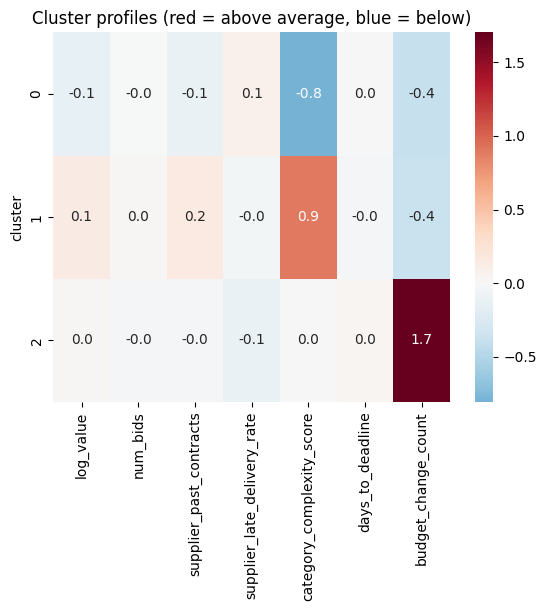

In [14]:
# Cluster centres in scaled units: 0 = average, +1 = one standard deviation above average
profile = pd.DataFrame(km.cluster_centers_, columns=features)

# Heatmap shows what makes each cluster different
sns.heatmap(profile, annot=True, fmt='.1f', cmap='RdBu_r', center=0)
plt.ylabel('cluster'); plt.title('Cluster profiles (red = above average, blue = below)');

In [15]:
# Same thing in original units
df.groupby('cluster')[features].mean().round(2)

,log_value,num_bids,supplier_past_contracts,supplier_late_delivery_rate,category_complexity_score,days_to_deadline,budget_change_count
cluster,,,,,,,
0,4.34,5.00,6.68,0.21,1.82,64.04,0.45
1,4.43,5.05,7.42,0.19,4.26,62.40,0.46
2,4.39,4.94,6.90,0.18,2.99,64.74,2.29


**A:**
- **Cluster 0:** simple tenders (low complexity), few budget changes.
- **Cluster 1:** complex tenders, few budget changes.
- **Cluster 2:** tenders with **many budget changes**.

Number of bids, supplier history and deadlines are almost the same in all three groups.

## 7. Screens: do some groups look riskier?

In [16]:
# Risk screens: compare outcomes that were NOT used for clustering
screens = df.groupby('cluster').agg(
    tenders=('cluster', 'size'),                                  # number of tenders
    delayed_rate=('award_delayed', 'mean'),                       # share of delayed awards
    manual_review_rate=('has_manual_review_flag', 'mean'),        # share flagged for manual review
    avg_bids=('num_bids', 'mean'),                                # average number of bids
    single_bid_rate=('num_bids', lambda s: (s == 1).mean()),      # share with only one bid (no competition)
).round(2)
screens

,tenders,delayed_rate,manual_review_rate,avg_bids,single_bid_rate
cluster,,,,,
0,1079,0.31,0.19,5.00,0.01
1,960,0.47,0.18,5.05,0.03
2,461,0.48,0.20,4.94,0.02


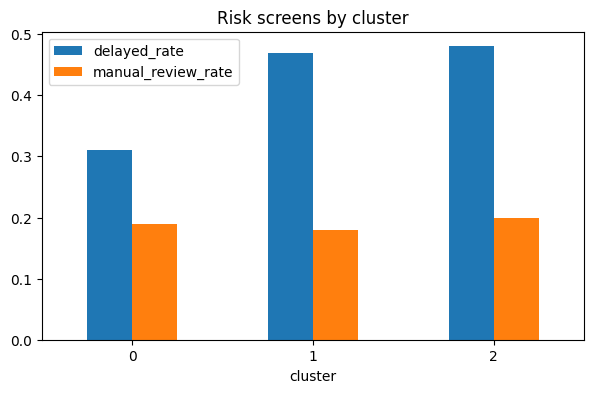

In [17]:
# Bar chart of the two risk rates per cluster
screens[['delayed_rate', 'manual_review_rate']].plot.bar(figsize=(7, 4), rot=0)
plt.title('Risk screens by cluster');

In [18]:
# Procurement method mix in each cluster (each row adds up to 1)
pd.crosstab(df['cluster'], df['procurement_method'], normalize='index').round(2)

procurement_method,direct_award,framework_calloff,open_tender,selective_tender
cluster,,,,
0,0.14,0.15,0.49,0.22
1,0.15,0.16,0.48,0.21
2,0.18,0.14,0.52,0.17


**A:** Clusters 1 and 2 (complex or many budget changes) are delayed more often (about 47–48%) than cluster 0 (about 31%). Manual review and procurement method look the same everywhere.
This is a **flag for further checking**, not proof of anything.

## 8. Agglomerative clustering (and dendrogram)

In [19]:
# Agglomerative clustering: start with every tender alone, keep merging the closest groups
agg = AgglomerativeClustering(n_clusters=3).fit(X_scaled)   # ward linkage
print('Silhouette:', round(silhouette_score(X_scaled, agg.labels_), 3))

# Compare with K-Means: how many tenders land in the same groups?
pd.crosstab(df['cluster'], agg.labels_, rownames=['k-means'], colnames=['agglomerative'])

Silhouette: 0.06


agglomerative,0,1,2
k-means,,,
0,787,125,167
1,347,540,73
2,375,71,15


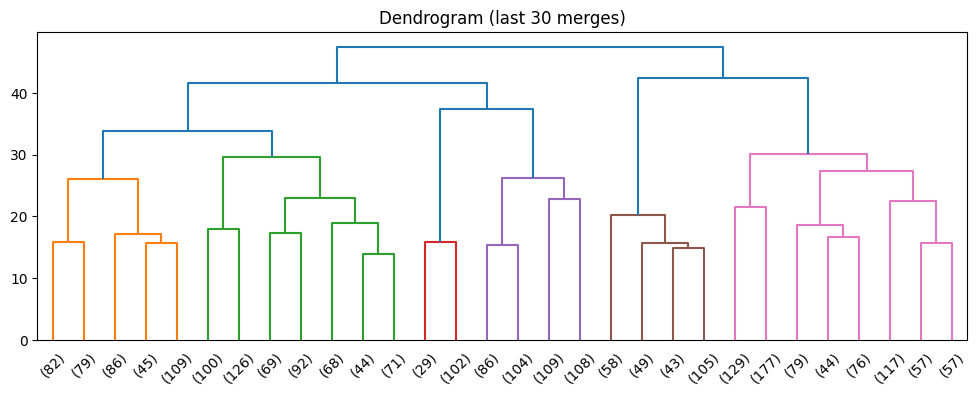

In [20]:
# Dendrogram: the tree of merges (tall vertical gaps = natural places to cut)
tree = linkage(X_scaled, method='ward')
plt.figure(figsize=(12, 4))
dendrogram(tree, truncate_mode='lastp', p=30)   # show only the last 30 merges so it stays readable
plt.title('Dendrogram (last 30 merges)');

**A:** Agglomerative gives a lower silhouette (about 0.06) and only partly agrees with K-Means. No long gaps in the dendrogram, so no obvious place to cut.

## 9. DBSCAN (k-distance plot to pick eps)

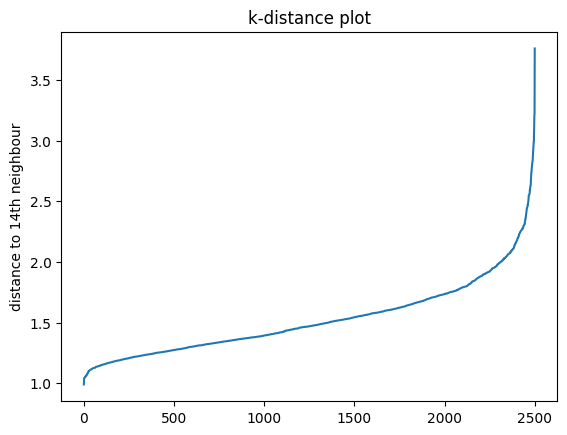

In [21]:
# DBSCAN needs two settings: min_samples and eps (search radius)
min_samples = 14   # rule of thumb: 2 x number of features

# k-distance plot: distance from each tender to its 14th nearest neighbour, sorted
# A good eps is where the curve bends upwards (the "knee")
dist = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled).kneighbors(X_scaled)[0][:, -1]
plt.plot(np.sort(dist)); plt.title('k-distance plot'); plt.ylabel(f'distance to {min_samples}th neighbour');

In [22]:
# Try a few eps values and count clusters and noise (label -1 = noise / outlier)
for eps in [1.0, 1.3, 1.6, 2.0]:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
    print(f'eps={eps}: clusters={len(set(labels) - {-1})}, noise={(labels == -1).mean():.0%}')

eps=1.0: clusters=1, noise=99%
eps=1.3: clusters=1, noise=43%
eps=1.6: clusters=1, noise=9%
eps=2.0: clusters=1, noise=1%


**A:** DBSCAN never finds more than **one** cluster. It only separates a dense core from outlier tenders. So the data is one big cloud, not separate groups.

In [23]:
# Bonus: which tenders does DBSCAN call outliers?
df['outlier'] = DBSCAN(eps=1.6, min_samples=min_samples).fit_predict(X_scaled) == -1   # True = outlier

# Compare average features and delay rate: outliers vs normal tenders
df.groupby('outlier')[features + ['award_delayed']].mean().round(2)

,log_value,num_bids,supplier_past_contracts,supplier_late_delivery_rate,category_complexity_score,days_to_deadline,budget_change_count,award_delayed
outlier,,,,,,,,
False,4.37,4.93,6.88,0.19,2.97,63.39,0.71,0.39
True,4.46,5.76,8.26,0.30,3.01,65.13,1.65,0.48


**A:** The outliers are unusual tenders: more budget changes, suppliers with higher late-delivery rates, more bids. They are delayed more often, so they are a good **shortlist to check**.

## 10. PCA: picture of the clusters in 2D

Variance kept by 2 components: 30%


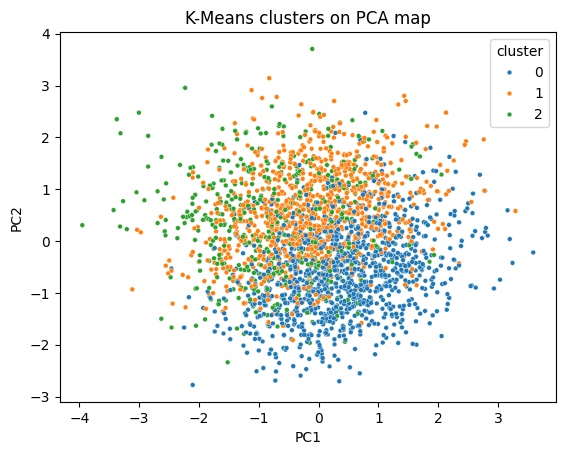

In [24]:
# PCA: summarise the 7 features with 2 new columns so we can draw them
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print(f'Variance kept by 2 components: {pca.explained_variance_ratio_.sum():.0%}')

# Each dot is one tender, coloured by its K-Means cluster
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df['cluster'], palette='tab10', s=12)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('K-Means clusters on PCA map');

**A:** 2 components keep only about 30% of the variation, and the clusters touch each other. K-Means is slicing one cloud, not finding separate groups.

## 11. Compare the algorithms

In [25]:
# Summary table: clusters found and silhouette score for each method
pd.DataFrame({
    'algorithm': ['K-Means (k=3)', 'Agglomerative (k=3)', 'DBSCAN'],
    'clusters': [3, 3, 1],
    'silhouette': [round(silhouette_score(X_scaled, km.labels_), 3),
                   round(silhouette_score(X_scaled, agg.labels_), 3), None],   # DBSCAN: only 1 cluster, so no score
})

,algorithm,clusters,silhouette
0,K-Means (k=3),3,0.114
1,Agglomerative (k=3),3,0.060
2,DBSCAN,1,NaN


## 12. Classification: predict `award_delayed`
Now there **is** a label, so this is supervised. Does adding the cluster number help?

In [26]:
# Tools for supervised learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

# Features: numeric columns + text columns turned into 0/1 dummy columns
X_clf = pd.get_dummies(df[features + ['has_manual_review_flag', 'procurement_method', 'category',
                                      'agency_type', 'supplier_region']], drop_first=True)
y = df['award_delayed']   # target: 1 = award was delayed

# Keep 25% aside for testing; stratify keeps the same share of delays in both parts
X_train, X_test, y_train, y_test = train_test_split(X_clf, y, test_size=0.25, random_state=42, stratify=y)

# Baseline to beat: always guess "not delayed"
print('Baseline (always "not delayed"):', round(1 - y_test.mean(), 2), 'accuracy')

Baseline (always "not delayed"): 0.6 accuracy


In [27]:
# Two classifiers to compare
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42),
}
for name, model in models.items():
    sc = StandardScaler().fit(X_train)                 # learn scaling on training data only
    model.fit(sc.transform(X_train), y_train)          # train the model
    # ROC-AUC: 0.5 = random guessing, 1 = perfect
    auc = roc_auc_score(y_test, model.predict_proba(sc.transform(X_test))[:, 1])
    print(f'{name}: ROC-AUC = {auc:.3f}')

Logistic Regression: ROC-AUC = 0.697
Random Forest: ROC-AUC = 0.666


In [28]:
# Same logistic regression + cluster dummies: does knowing the cluster help?
X_clf2 = X_clf.join(pd.get_dummies(df['cluster'], prefix='cluster', drop_first=True))
X_tr2, X_te2 = X_clf2.loc[X_train.index], X_clf2.loc[X_test.index]   # same train/test split as before
sc2 = StandardScaler().fit(X_tr2)
lr2 = LogisticRegression(max_iter=2000).fit(sc2.transform(X_tr2), y_train)
print('Logistic Regression + cluster: ROC-AUC =', round(roc_auc_score(y_test, lr2.predict_proba(sc2.transform(X_te2))[:, 1]), 3))

Logistic Regression + cluster: ROC-AUC = 0.697


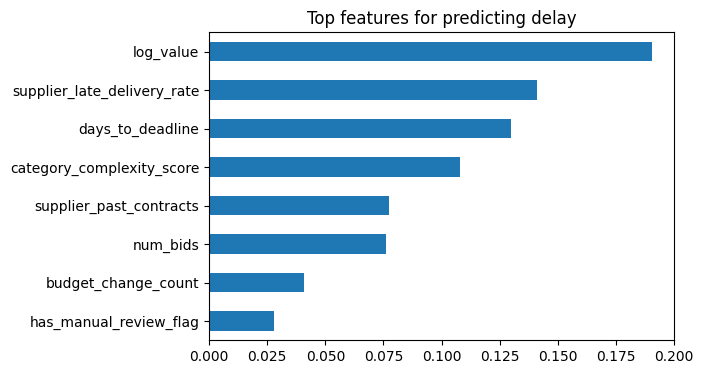

In [29]:
# Which features matter most? (Random Forest)
rf = models['Random Forest']

# Show the 8 most important features as a bar chart
pd.Series(rf.feature_importances_, index=X_clf.columns).sort_values().tail(8).plot.barh(figsize=(6, 4))
plt.title('Top features for predicting delay');

**A:** Classification works better than clustering for this question. Adding the cluster number does not help, because the clusters are built from the same features the model already sees.

## 13. Conclusions
- **Weak clusters:** silhouette is about 0.1 and DBSCAN finds one cloud. The tenders don't form strong natural groups.
- **K-Means still gives useful segments:** simple / complex / many budget changes. The last two are delayed more often.
- **DBSCAN outliers** are a practical shortlist of unusual tenders to review.
- **Classification** (predicting delay) is the stronger tool here; contract value, supplier late-delivery rate, deadline and complexity matter most. AUC is about 0.70 (0.5 = guessing), so only moderate.
- **Next step:** I need data with **bidder IDs per tender**, e.g. the Croatian GTI data. Then we can build the co-bidding network in Python